### 다중분류


- 손글씨 분류
  - total: 70,000 개
  - training_dataset: 60,000 개
  - test_dataset: 10,000 개
  - image shape : 28 * 28 (pixel)
  - class 10 개 : 0 ~ 9 (까지의 숫자 손글씨)

In [88]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import os
os.makedirs('results ',exist_ok=True)
print(os.getcwd())

/content


In [ ]:
# 내 구글 드라이브와 연동
# from google.colab import drive
# drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [90]:
# 장치 선택
device = 'cuda' if torch.cuda.is_available else 'cpu'
print(device)

cuda


In [91]:
transform=transforms.ToTensor()

train_DS= datasets.MNIST(
    root='/content/drive/MyDrive/Colab Notebooks/data',
    train=True,
    download=True,
    transform=transform
)

test_DS= datasets.MNIST(
    root='/content/drive/MyDrive/Colab Notebooks/data',
    train=False,
    download=True,
    transform=transform
)

In [92]:
print(train_DS)
print(test_DS)

Dataset MNIST
    Number of datapoints: 60000
    Root location: /content/drive/MyDrive/Colab Notebooks/data
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset MNIST
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/Colab Notebooks/data
    Split: Test
    StandardTransform
Transform: ToTensor()


In [93]:
train_DS.classes

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [94]:
train_DS.class_to_idx

{'0 - zero': 0,
 '1 - one': 1,
 '2 - two': 2,
 '3 - three': 3,
 '4 - four': 4,
 '5 - five': 5,
 '6 - six': 6,
 '7 - seven': 7,
 '8 - eight': 8,
 '9 - nine': 9}

In [95]:
train_DS.data.shape

torch.Size([60000, 28, 28])

In [96]:
train_DS.data[0]

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   

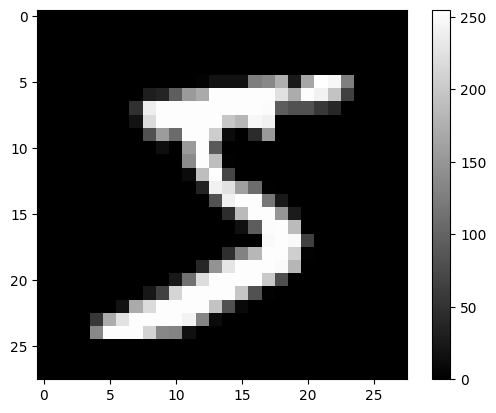

In [97]:
plt.imshow(train_DS.data[0], cmap='gray')
plt.colorbar()

In [98]:
print(train_DS.targets)
print(train_DS.targets.shape)

tensor([5, 0, 4,  ..., 5, 6, 8])
torch.Size([60000])


#### DataLoader

In [99]:
BATCH_SIZE = 32
train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size= BATCH_SIZE, shuffle=True)

In [100]:
x_batch, y_batch =next(iter(train_DL))  # transform.ToTensor()이 실제로 실행되는 때

# 원본데이터
print(type(train_DS.data))
print(train_DS.data.shape)  # torch.Size([instance, row, col])
print(train_DS.data.dtype)
print(train_DS.data[0].shape)

# batch 데이터
print(type(x_batch))
print(x_batch.shape)  # torch.Size([batch_instance, color_channel, row, col]), ToTensor()의 결과 = 이미지 한 장을 (C, H, W)로 변환

<class 'torch.Tensor'>
torch.Size([60000, 28, 28])
torch.uint8
torch.Size([28, 28])
<class 'torch.Tensor'>
torch.Size([32, 1, 28, 28])


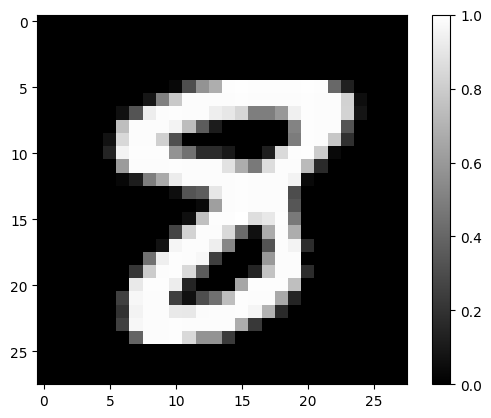

In [101]:
plt.imshow(x_batch[0].permute(1,2,0), cmap='gray')  # 차원이 변경되었기 때문에 .permute()로 차원의 위치를 맞춰주고 출력
plt.colorbar()

In [102]:
class MLP(nn.Module):
  def __init__(self,n_feature,n_class):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(n_feature, 100),
                                nn.ReLU(),
                                nn.Linear(100, n_class)).to(device)

  def forward(self, x):
    x = torch.flatten(x, start_dim=1) # (32,1,28,28)을 dim=1 에서 펼치면 (32, 1*28*28(=784)))이 됨
    x = self.linear(x)
    return x

image, label = train_DS[0]
n_feature = image.numel() # 이미지 한 장의 전체 원소 수
n_class = len(train_DS.classes)

In [103]:
x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

flat_images = torch.flatten(x_batch, start_dim=1)
print(flat_images.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32, 784])


In [104]:
model = MLP(n_feature, n_class)
print(model)

model.eval()
with torch.no_grad():
  print(model(x_batch.to(device)).shape)

MLP(
  (linear): Sequential(
    (0): Linear(in_features=784, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=10, bias=True)
  )
)
torch.Size([32, 10])


In [105]:
LR = 1e-3
EPOCH = 5

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

In [106]:
def train(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    tr_loss = 0

    model.train()
    for x_batch, y_batch in dataloader:
        x, y = x_batch.to(device), y_batch.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches

    return tr_loss.item()

In [107]:
# from torch import optim

# LR = 1e-3
# EPOCH = 15

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=LR)

# def train(model, train_DL, criterion, optimizer, device):
#   # loss_history = []
#   num_batches = len(train_DL.dataset)

#   model.train()
#   for ep in range(EPOCH):
#     tr_loss = 0
#     for x_batch, y_batch in train_DL:
#       x_batch, y_batch = x_batch.to(device), y_batch.to(device)

#       y_hat = model(x_batch)
#       loss = criterion(y_hat, y_batch)

#       optimizer.zero_grad()
#       loss.backward()
#       optimizer.step()

#       loss_b = loss.item() * x_batch.shape[0]
#       tr_loss += loss
#     tr_loss /= num_batches
#     return tr_loss.item()
    # loss_history.append(tr_loss.item())
    # print(f'Epoch {ep+1:.4f}, TR Loss {tr_loss:.4f}')

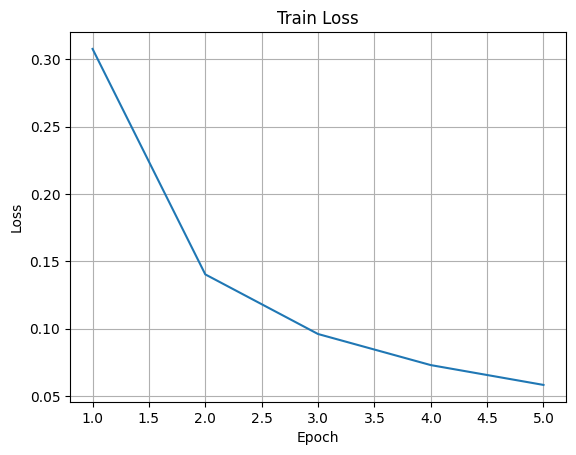

In [108]:
loss_history = []
for ep in range(EPOCH):
  tr_loss = train(train_DL, model, loss_fn, optimizer, device)
  loss_history.append(tr_loss)

plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train Loss')
plt.grid()



> 모델 저장하고 불러오기



In [116]:
save_dir = '/content/drive/MyDrive/Colab Notebooks/results'
os.makedirs(save_dir, exist_ok=True)
save_model_path = f'{save_dir}/MLP.pt'
torch.save(model.state_dict(), save_model_path)

In [117]:
load_model = MLP(n_feature, n_class)
load_model.load_state_dict(torch.load(save_model_path, map_location=device))

<All keys matched successfully>

#### 모델 테스트

In [115]:
model.eval()
with torch.no_grad():
  rcorrect= 0 # 잘분류된 값을 누적으로 넣는 변수
  for x_batch, y_batch in test_DL :
    x, y = x_batch.to(device), y_batch.to(device)

    y_hat = model(x)
    pred = y_hat.argmax(dim=1)
    print(y_hat.shape)
    print(pred)

    correct_b = torch.sum(pred == y).item()
    rcorrect += correct_b

    accuracy_e = rcorrect / len(test_DL.dataset)

    print(f'Test accuracy: {rcorrect} / {len(test_DL.dataset)} ({accuracy_e*100:.1f}%)')

torch.Size([32, 10])
tensor([4, 7, 8, 6, 4, 3, 8, 7, 1, 1, 7, 5, 8, 4, 5, 3, 9, 3, 8, 2, 3, 9, 4, 4,
        7, 0, 2, 3, 2, 9, 9, 7], device='cuda:0')
Test accuracy: 31 / 10000 (0.3%)
torch.Size([32, 10])
tensor([5, 4, 3, 5, 6, 0, 6, 8, 8, 9, 0, 7, 6, 3, 1, 2, 1, 3, 7, 5, 7, 0, 6, 4,
        7, 3, 1, 1, 6, 6, 2, 8], device='cuda:0')
Test accuracy: 60 / 10000 (0.6%)
torch.Size([32, 10])
tensor([6, 8, 2, 8, 1, 1, 0, 9, 1, 9, 4, 3, 6, 3, 2, 9, 2, 0, 1, 9, 9, 7, 8, 3,
        8, 0, 7, 5, 7, 1, 0, 2], device='cuda:0')
Test accuracy: 91 / 10000 (0.9%)
torch.Size([32, 10])
tensor([5, 0, 6, 2, 6, 5, 7, 9, 4, 9, 7, 4, 8, 3, 0, 1, 7, 5, 8, 8, 1, 2, 6, 8,
        9, 7, 5, 9, 9, 2, 9, 6], device='cuda:0')
Test accuracy: 121 / 10000 (1.2%)
torch.Size([32, 10])
tensor([0, 7, 4, 4, 4, 4, 2, 5, 5, 0, 7, 6, 8, 0, 2, 0, 9, 2, 4, 4, 7, 9, 1, 7,
        3, 5, 4, 6, 6, 0, 3, 5], device='cuda:0')
Test accuracy: 153 / 10000 (1.5%)
torch.Size([32, 10])
tensor([0, 5, 6, 6, 9, 0, 7, 3, 5, 2, 9, 0, 0, 9, 6, 7, 6

In [118]:
def evaluate(dataloader, model, loss_fn, device):
  model.eval()
  with torch.no_grad():
    for x_batch, y_batch in dataloader:
        x, y = x_batch.to(device), y_batch.to(device)
        y_hat = model(x)
        pred = y_hat.argmax(dim=1)
        val_loss = loss_fn(y_hat, y).item()
    return val_loss, pred

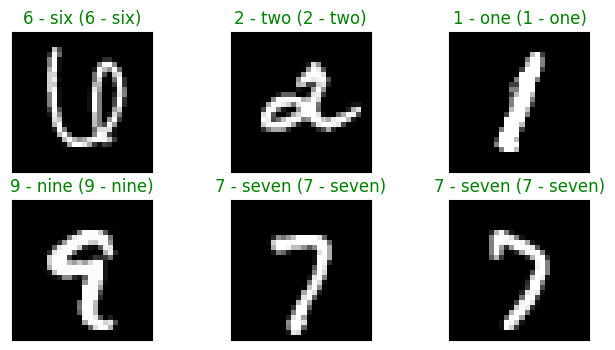

In [120]:
model.eval()
with torch.no_grad():
  x_batch, y_batch = next(iter(test_DL))
  y_hat = model(x_batch.to(device))
  pred = y_hat.argmax(dim=1)

x_batch = x_batch.to('cpu')

plt.figure(figsize=(8,4))
for idx in range(6):
  plt.subplot(2,3, idx+1, xticks=[], yticks=[])
  plt.imshow(x_batch[idx].permute(1,2,0), cmap='gray')
  pred_class = test_DL.dataset.classes[pred[idx]]
  true_class = test_DL.dataset.classes[y_batch[idx]]
  plt.title(f'{pred_class} ({true_class})',
            color='g' if pred_class == true_class else 'r')

.to(device)
- GPU 와 CPU 는 다른 메모리 사용
- DataLoader 에서 데이터를 꺼내오면 CPU에 올라옴
- GPU 에서 실행하려면 CPU 에 있는 데이터나 모델을 GPU 의 메모리로 옮겨야 함
  - 모델을 GPU로 이동할 때
  - 학습데이터를 GPU로 이동할 때
  - 테스트데이터를 GPU로 이동할 때